In [213]:
import numpy as np
import matplotlib.pyplot as plt
import random as rnd
from scipy import stats
from scipy.optimize import brentq

In [214]:
# variabelen
H_s = 7 # wave height
h = 25 # water depth
g = 9.81 # gravitational constant
T_p = 11.49 # peak period
f_p = 1 / T_p 
N = 1000 # number of waves
f = np.linspace(0.01, 0.5, N) 
df = f[1] - f[0]
gamma = 3.3
A_gamma = 1 - 0.287 * np.log(gamma)
sigma_1 = 0.07
sigma_2 = 0.09

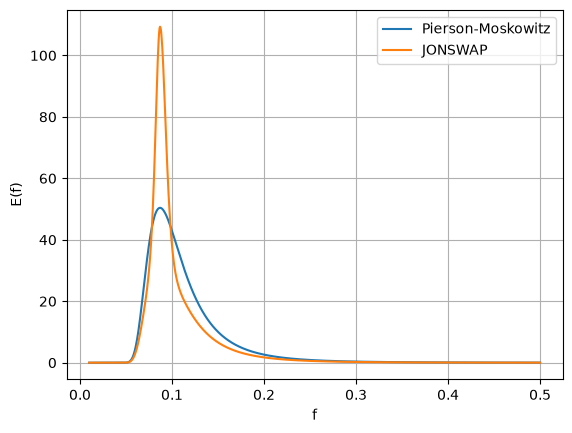

In [215]:
# berekening E's
E_PM = 5 / 16 * H_s ** 2 * f_p ** 4 * f ** -5 * np.exp(-5 / 4 * (f_p / f) ** 4)
E_JS = np.zeros(len(f))

# berekening E_JS in loop om rekening te houden met beide waarden voor sigma
for i in range(len(E_JS)):
    if f[i] <= f_p:
        sigma = sigma_1
    else:
        sigma = sigma_2
    E_JS[i] = A_gamma * E_PM[i] * gamma ** np.exp(-(f[i]-f_p) ** 2 / (2 * sigma ** 2 * f_p ** 2))

plt.plot(f, E_PM, label="Pierson-Moskowitz")
plt.plot(f, E_JS, label="JONSWAP")
plt.xlabel("f")
plt.ylabel("E(f)")
plt.legend()
plt.grid()

0.5103054407045933


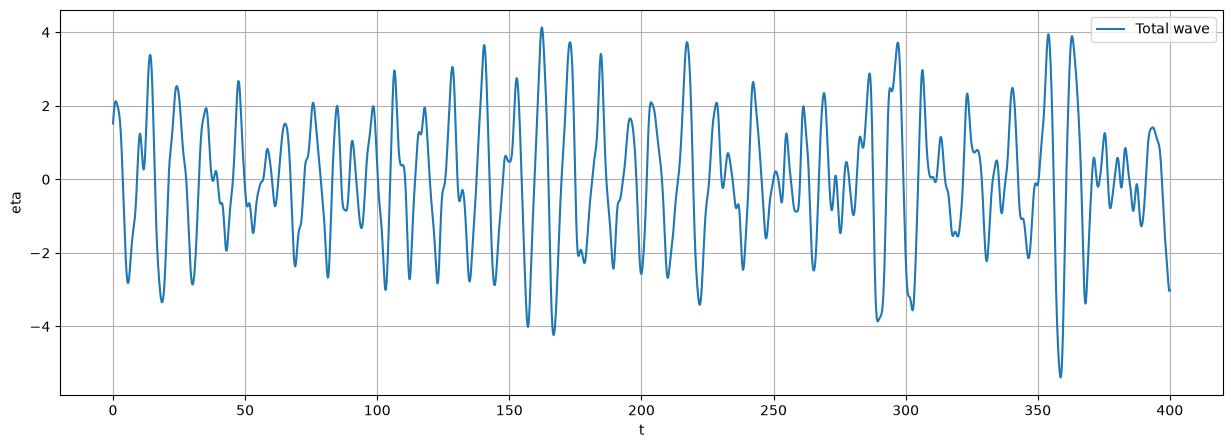

In [216]:
# rnd.seed(5) # om random phase shift gelijk te houden per simulatie

# alpha als willekeurige phase shift tussen 0 en 2pi
alpha = [rnd.randrange(0, 200) * np.pi / 100 for _ in range(N)]

def calculate_k(f, h):
    omega = 2 * np.pi * f

    def dispersion(k):
        return g * k * np.tanh(k * h) - omega**2

    return brentq(dispersion, 1e-8, 100)

t = np.linspace(0, 400, 10000) # tijdstappen
eta = np.zeros(len(t)) # golfhoogte
k = [calculate_k(fi, h) for fi in f] # wavenumbers per golf
lambd = np.array(2 * np.pi) / k
slope = np.zeros(len(t))


for i in range(len(eta)): # loop over elke tijdstap om hier de wave height te bepalen
    for j in range(len(f)): # loop over elke frequentie om de samengestelde golf te bepalen
        a = np.sqrt(2 * E_JS[j] * df) # amplitude van de golf
        phase = 2 * np.pi * f[j] * t[i] + alpha[j]
        eta[i] += a * np.cos(phase) # opsomming van de individuele golven
        slope[i] += -a * k[j] * np.sin(phase)

plt.figure(figsize=(15,5))
plt.plot(t, eta, label="Total wave")
plt.xlabel("t")
plt.ylabel("eta")
plt.legend()
plt.grid()

max_steep = np.max(np.abs(slope))
print(max_steep)

individual_steepness = []

for j in range(len(f)):
    a = np.sqrt(2 * E_JS[j] * df)
    individual_steepness.append(a * k[j])

In [217]:
m0, m1, m2, m_min1 = [np.sum(f ** p * E_JS * df) for p in [0, 1, 2, -1]]
H_m0 = 4 * np.sqrt(m0)
T_m01 = m0 / m1
T_m02 = np.sqrt(m0 / m2)
T_m_min1 = m_min1 / m0